In [1]:

!pip install fairlearn scikit-learn pandas numpy matplotlib seaborn


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference
)

print("AI Fairness Research Environment Ready!")


AI Fairness Research Environment Ready!


In [3]:

# STEP 2: GENERATE SYNTHETIC RECRUITMENT DATASET

import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

# Number of applicants
n = 5000

# Generate applicant characteristics
data = pd.DataFrame({
    "applicant_id": range(1, n + 1),

    "gender_group": np.random.choice(
        ["Male", "Female"], n, p=[0.55, 0.45]
    ),

    "race_group": np.random.choice(
        ["Group_A", "Group_B", "Group_C"],
        n,
        p=[0.50, 0.30, 0.20]
    ),

    "education_level": np.random.choice(
        [1, 2, 3, 4], n,
        p=[0.15, 0.30, 0.40, 0.15]
    ),

    "years_experience": np.random.randint(0, 16, n),

    "skills_score": np.random.normal(70, 12, n).clip(0, 100),

    "assessment_score": np.random.normal(68, 14, n).clip(0, 100)
})

# Define an objective qualification score
data["qualification_score"] = (
    0.20 * data["education_level"] / 4 * 100
    + 0.30 * data["years_experience"] / 15 * 100
    + 0.25 * data["skills_score"]
    + 0.25 * data["assessment_score"]
)

# Define synthetic qualification label
data["objectively_qualified"] = (
    data["qualification_score"] >= 60
).astype(int)

# Create baseline historical hiring decisions
data["baseline_decision"] = (
    data["qualification_score"] >= 65
).astype(int)

# Introduce a deliberate historical gender disparity
gender_penalty = np.where(
    data["gender_group"] == "Female", 8, 0
)

biased_score = data["qualification_score"] - gender_penalty

data["biased_historical_decision"] = (
    biased_score >= 65
).astype(int)

# Inspect dataset
print("Dataset generated successfully!")
print("Shape:", data.shape)

display(data.head(10))


Dataset generated successfully!
Shape: (5000, 11)


,applicant_id,gender_group,race_group,education_level,years_experience,skills_score,assessment_score,qualification_score,objectively_qualified,baseline_decision,biased_historical_decision
0,1,Male,Group_A,2,11,60.362985,90.779653,69.785659,1,1,1
1,2,Female,Group_A,2,5,58.935363,83.502363,55.609432,0,0,0
2,3,Female,Group_C,2,12,89.028150,70.965094,73.998311,1,1,1
3,4,Female,Group_A,3,15,81.471257,68.475130,82.486597,1,1,1
4,5,Male,Group_C,3,12,93.323009,74.153140,80.869037,1,1,1
5,6,Male,Group_A,4,3,70.665440,70.724800,61.347560,1,0,0
6,7,Male,Group_B,1,3,73.455035,56.908137,43.590793,0,0,0
7,8,Female,Group_C,3,13,66.793701,62.231268,73.256242,1,1,1
8,9,Female,Group_A,3,10,66.555014,95.450050,75.501266,1,1,1
9,10,Female,Group_A,3,6,57.497357,100.000000,66.374339,1,1,0


In [4]:

# STEP 2B: DATASET QUALITY CHECK

print("Missing values:")
print(data.isnull().sum())

print("\nGender distribution:")
print(data["gender_group"].value_counts())

print("\nRace distribution:")
print(data["race_group"].value_counts())

print("\nQualification distribution:")
print(data["objectively_qualified"].value_counts())

print("\nBaseline selection rate:")
print(data.groupby("gender_group")["baseline_decision"].mean())

print("\nBiased historical selection rate:")
print(data.groupby("gender_group")["biased_historical_decision"].mean())


Missing values:
applicant_id                  0
gender_group                  0
race_group                    0
education_level               0
years_experience              0
skills_score                  0
assessment_score              0
qualification_score           0
objectively_qualified         0
baseline_decision             0
biased_historical_decision    0
dtype: int64

Gender distribution:
gender_group
Male      2748
Female    2252
Name: count, dtype: int64

Race distribution:
race_group
Group_A    2576
Group_B    1461
Group_C     963
Name: count, dtype: int64

Qualification distribution:
objectively_qualified
1    2838
0    2162
Name: count, dtype: int64

Baseline selection rate:
gender_group
Female    0.404085
Male      0.403202
Name: baseline_decision, dtype: float64

Biased historical selection rate:
gender_group
Female    0.189609
Male      0.403202
Name: biased_historical_decision, dtype: float64


In [5]:

# STEP 3: TRAIN TWO RECRUITMENT MODELS

features = [
    "education_level",
    "years_experience",
    "skills_score",
    "assessment_score"
]

X = data[features]

y_baseline = data["baseline_decision"]
y_biased = data["biased_historical_decision"]

X_train, X_test, y_base_train, y_base_test = train_test_split(
    X, y_baseline, test_size=0.2, random_state=42
)

_, _, y_bias_train, y_bias_test = train_test_split(
    X, y_biased, test_size=0.2, random_state=42
)

baseline_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

biased_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

baseline_model.fit(X_train, y_base_train)
biased_model.fit(X_train, y_bias_train)

data.loc[X_test.index, "baseline_prediction"] = baseline_model.predict(X_test)
data.loc[X_test.index, "biased_prediction"] = biased_model.predict(X_test)

print("Both models trained successfully!")


Both models trained successfully!


In [6]:

# STEP 4: FAIRNESS COMPARISON

test_data = data.loc[X_test.index].copy()

for model in ["baseline_prediction", "biased_prediction"]:

    print("\nMODEL:", model)

    print(
        test_data.groupby("gender_group")[model].mean()
    )

    print(
        "\nSelection rate by race:"
    )

    print(
        test_data.groupby("race_group")[model].mean()
    )

    print("\nOverall selection rate:",
          test_data[model].mean())



MODEL: baseline_prediction
gender_group
Female    0.438228
Male      0.416813
Name: baseline_prediction, dtype: float64

Selection rate by race:
race_group
Group_A    0.434701
Group_B    0.419118
Group_C    0.411458
Name: baseline_prediction, dtype: float64

Overall selection rate: 0.426

MODEL: biased_prediction
gender_group
Female    0.310023
Male      0.329247
Name: biased_prediction, dtype: float64

Selection rate by race:
race_group
Group_A    0.330224
Group_B    0.330882
Group_C    0.281250
Name: biased_prediction, dtype: float64

Overall selection rate: 0.321


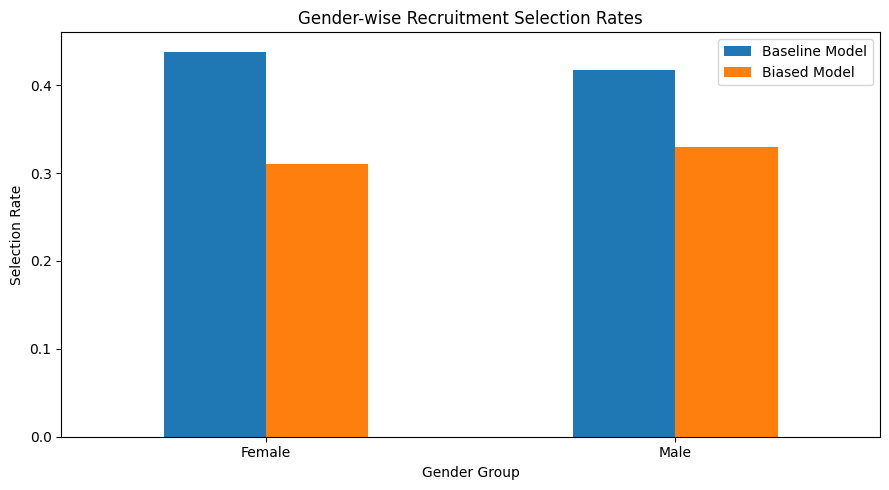

In [7]:

# STEP 5: SELECTION RATE VISUALISATION

selection_rates = test_data.groupby("gender_group")[
    ["baseline_prediction", "biased_prediction"]
].mean()

selection_rates.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Gender-wise Recruitment Selection Rates")
plt.ylabel("Selection Rate")
plt.xlabel("Gender Group")
plt.xticks(rotation=0)
plt.legend(["Baseline Model", "Biased Model"])
plt.tight_layout()
plt.show()


In [8]:

# STEP 6: CONTROLLED FAIRNESS EXPERIMENT

# Same train-test split for both models
train_idx, test_idx = train_test_split(
    data.index,
    test_size=0.2,
    random_state=42
)

# Baseline model: no protected attributes
X_base = data[features]

baseline_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

baseline_model.fit(
    X_base.loc[train_idx],
    data.loc[train_idx, "baseline_decision"]
)

# Biased model: gender explicitly included
X_biased = pd.get_dummies(
    data[features + ["gender_group"]],
    columns=["gender_group"],
    dtype=int
)

biased_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

biased_model.fit(
    X_biased.loc[train_idx],
    data.loc[train_idx, "biased_historical_decision"]
)

# Predictions on identical test applicants
test_data = data.loc[test_idx].copy()

test_data["baseline_prediction"] = baseline_model.predict(
    X_base.loc[test_idx]
)

test_data["biased_prediction"] = biased_model.predict(
    X_biased.loc[test_idx]
)

# Compare selection rates
print("GENDER-WISE SELECTION RATES")

print(
    test_data.groupby("gender_group")[
        ["baseline_prediction", "biased_prediction"]
    ].mean()
)

print("\nRACE-WISE SELECTION RATES")

print(
    test_data.groupby("race_group")[
        ["baseline_prediction", "biased_prediction"]
    ].mean()
)


GENDER-WISE SELECTION RATES
              baseline_prediction  biased_prediction
gender_group                                        
Female                   0.438228           0.188811
Male                     0.416813           0.411559

RACE-WISE SELECTION RATES
            baseline_prediction  biased_prediction
race_group                                        
Group_A                0.434701           0.332090
Group_B                0.419118           0.301471
Group_C                0.411458           0.291667


In [10]:

# STEP 7: FAIRNESS METRICS - FIXED

for model in ["baseline_prediction", "biased_prediction"]:

    y_true = test_data["objectively_qualified"]
    y_pred = test_data[model]
    sensitive = test_data["gender_group"]

    print("\nMODEL:", model)

    dpd = demographic_parity_difference(
        y_true,
        y_pred,
        sensitive_features=sensitive
    )

    dpr = demographic_parity_ratio(
        y_true,
        y_pred,
        sensitive_features=sensitive
    )

    print("Demographic Parity Difference:", round(dpd, 4))
    print("Demographic Parity Ratio:", round(dpr, 4))



MODEL: baseline_prediction
Demographic Parity Difference: 0.0214
Demographic Parity Ratio: 0.9511

MODEL: biased_prediction
Demographic Parity Difference: 0.2227
Demographic Parity Ratio: 0.4588


,applicants,baseline_selection,biased_selection
intersection_group,,,
Female_Group_A,228,0.4342,0.1930
Female_Group_B,124,0.4274,0.1855
Female_Group_C,77,0.4675,0.1818
Male_Group_A,308,0.4351,0.4351
Male_Group_B,148,0.4122,0.3986
Male_Group_C,115,0.3739,0.3652


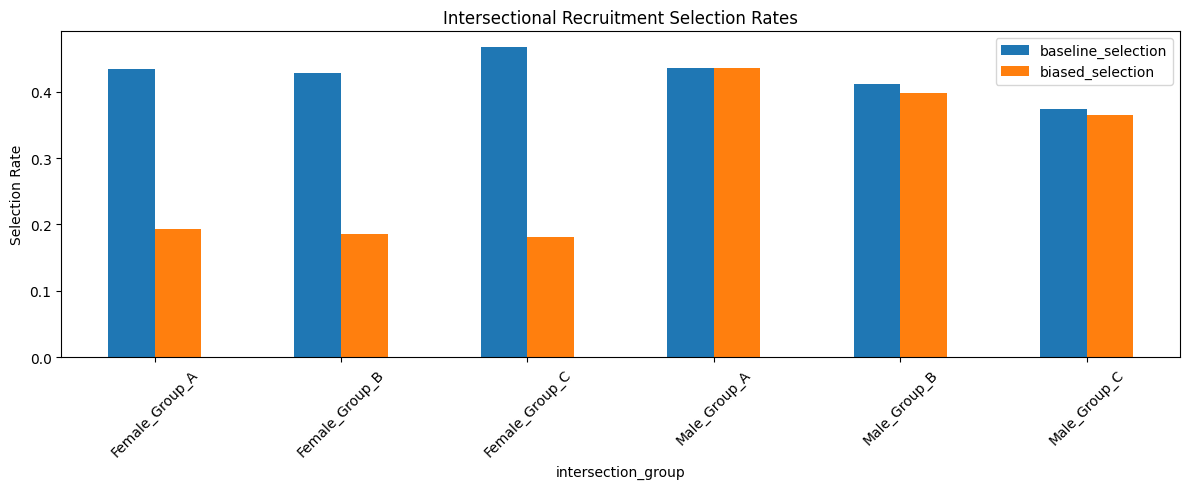

In [11]:

# STEP 8A: INTERSECTIONAL FAIRNESS

test_data["intersection_group"] = (
    test_data["gender_group"] + "_" +
    test_data["race_group"]
)

intersection_results = test_data.groupby(
    "intersection_group"
).agg(
    applicants=("applicant_id", "count"),
    baseline_selection=("baseline_prediction", "mean"),
    biased_selection=("biased_prediction", "mean")
)

display(intersection_results.round(4))

intersection_results[
    ["baseline_selection", "biased_selection"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Intersectional Recruitment Selection Rates")
plt.ylabel("Selection Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:

# STEP 8B: FALSE NEGATIVE RATE BY GENDER

from sklearn.metrics import confusion_matrix

def calculate_fnr(group):
    tn, fp, fn, tp = confusion_matrix(
        group["objectively_qualified"],
        group["biased_prediction"],
        labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) if (fn + tp) > 0 else 0

fnr_results = test_data.groupby("gender_group").apply(
    calculate_fnr,
    include_groups=False
)

print("False Negative Rate by Gender:")
print(fnr_results.round(4))


False Negative Rate by Gender:
gender_group
Female    0.6773
Male      0.3129
dtype: float64


In [13]:

# STEP 8C: MODEL PERFORMANCE

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_true = test_data["objectively_qualified"]

for model in ["baseline_prediction", "biased_prediction"]:

    y_pred = test_data[model]

    print("\n", model)

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall:", round(recall_score(y_true, y_pred), 4))
    print("F1 Score:", round(f1_score(y_true, y_pred), 4))



 baseline_prediction
Accuracy: 0.833
Precision: 1.0
Recall: 0.7184
F1 Score: 0.8361

 biased_prediction
Accuracy: 0.723
Precision: 1.0
Recall: 0.5329
F1 Score: 0.6953


In [14]:

# STEP 9: FAIRNESS MITIGATION

from fairlearn.reductions import ExponentiatedGradient, DemographicParity
from sklearn.linear_model import LogisticRegression

# Train on biased historical decisions
mitigation_model = ExponentiatedGradient(
    estimator=LogisticRegression(max_iter=1000),
    constraints=DemographicParity(),
    eps=0.02
)

mitigation_model.fit(
    X_biased.loc[train_idx],
    data.loc[train_idx, "biased_historical_decision"],
    sensitive_features=data.loc[train_idx, "gender_group"]
)

# Generate predictions
test_data["mitigated_prediction"] = mitigation_model.predict(
    X_biased.loc[test_idx]
)

print("Fairness mitigation completed!")


Fairness mitigation completed!


In [15]:

# STEP 9B: THREE-MODEL COMPARISON

models = [
    "baseline_prediction",
    "biased_prediction",
    "mitigated_prediction"
]

for model in models:

    print("\nMODEL:", model)

    print("Gender-wise selection:")
    print(test_data.groupby("gender_group")[model].mean().round(4))

    print("Overall accuracy:",
          round(accuracy_score(
              test_data["objectively_qualified"],
              test_data[model]
          ), 4))

    print("Recall:",
          round(recall_score(
              test_data["objectively_qualified"],
              test_data[model]
          ), 4))



MODEL: baseline_prediction
Gender-wise selection:
gender_group
Female    0.4382
Male      0.4168
Name: baseline_prediction, dtype: float64
Overall accuracy: 0.833
Recall: 0.7184

MODEL: biased_prediction
Gender-wise selection:
gender_group
Female    0.1888
Male      0.4116
Name: biased_prediction, dtype: float64
Overall accuracy: 0.723
Recall: 0.5329

MODEL: mitigated_prediction
Gender-wise selection:
gender_group
Female    0.3706
Male      0.3975
Name: mitigated_prediction, dtype: float64
Overall accuracy: 0.735
Recall: 0.602


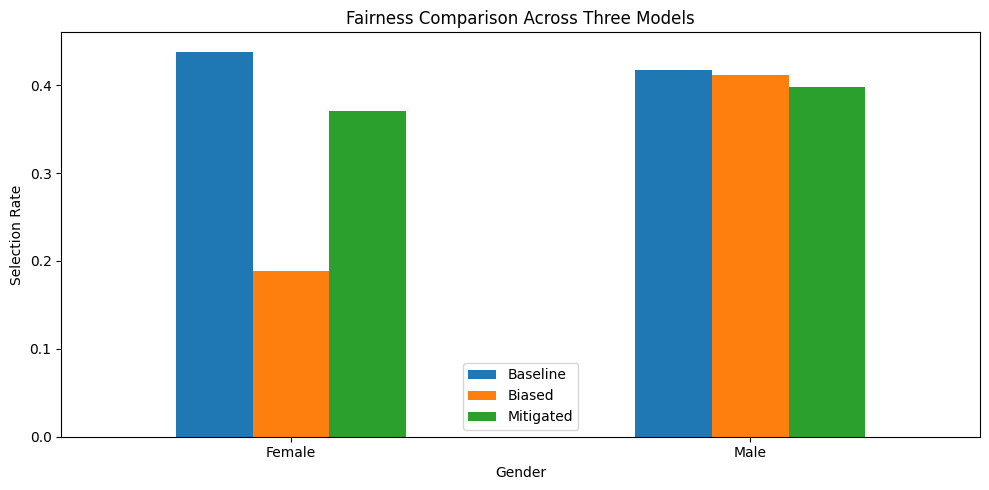

In [16]:

# STEP 9C: FINAL FAIRNESS COMPARISON CHART

comparison = test_data.groupby("gender_group")[
    models
].mean()

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Fairness Comparison Across Three Models")
plt.ylabel("Selection Rate")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.legend(["Baseline", "Biased", "Mitigated"])
plt.tight_layout()
plt.show()


In [17]:

# STEP 10: FINAL FAIRNESS AUDIT

from fairlearn.metrics import (
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    MetricFrame
)

results = []

for model in models:

    mf = MetricFrame(
        metrics={
            "Selection Rate": selection_rate,
            "True Positive Rate": true_positive_rate,
            "False Positive Rate": false_positive_rate
        },
        y_true=test_data["objectively_qualified"],
        y_pred=test_data[model],
        sensitive_features=test_data["gender_group"]
    )

    for group, row in mf.by_group.iterrows():

        results.append({
            "Model": model,
            "Gender": group,
            "Selection Rate": row["Selection Rate"],
            "True Positive Rate": row["True Positive Rate"],
            "False Positive Rate": row["False Positive Rate"]
        })

audit_results = pd.DataFrame(results)

display(audit_results.round(4))


,Model,Gender,Selection Rate,True Positive Rate,False Positive Rate
0,baseline_prediction,Female,0.4382,0.7490,0.0000
1,baseline_prediction,Male,0.4168,0.6959,0.0000
2,biased_prediction,Female,0.1888,0.3227,0.0000
3,biased_prediction,Male,0.4116,0.6871,0.0000
4,mitigated_prediction,Female,0.3706,0.5179,0.1629
5,mitigated_prediction,Male,0.3975,0.6637,0.0000


In [18]:

# STEP 10B: MODEL SUMMARY

summary = []

for model in models:

    y_true = test_data["objectively_qualified"]
    y_pred = test_data[model]

    summary.append({
        "Model": model,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "Gender DP Difference": demographic_parity_difference(
            y_true, y_pred,
            sensitive_features=test_data["gender_group"]
        )
    })

model_summary = pd.DataFrame(summary)

display(model_summary.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,Gender DP Difference
0,baseline_prediction,0.833,1.0000,0.7184,0.8361,0.0214
1,biased_prediction,0.723,1.0000,0.5329,0.6953,0.2227
2,mitigated_prediction,0.735,0.9249,0.6020,0.7293,0.0269


In [19]:

# STEP 10C: EXPORT RESULTS

data.to_csv("synthetic_recruitment_dataset.csv", index=False)
audit_results.to_csv("fairness_audit_results.csv", index=False)
model_summary.to_csv("model_performance_summary.csv", index=False)

print("All research outputs exported successfully!")


All research outputs exported successfully!


In [20]:

# STEP 12: FAIRNESS METRICS BY MODEL AND GENDER

from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate

for model in models:

    mf = MetricFrame(
        metrics={
            "Selection Rate": selection_rate,
            "True Positive Rate": true_positive_rate
        },
        y_true=test_data["objectively_qualified"],
        y_pred=test_data[model],
        sensitive_features=test_data["gender_group"]
    )

    print("\n", model.upper())
    display(mf.by_group.round(4))



 BASELINE_PREDICTION


,Selection Rate,True Positive Rate
gender_group,,
Female,0.4382,0.7490
Male,0.4168,0.6959



 BIASED_PREDICTION


,Selection Rate,True Positive Rate
gender_group,,
Female,0.1888,0.3227
Male,0.4116,0.6871



 MITIGATED_PREDICTION


,Selection Rate,True Positive Rate
gender_group,,
Female,0.3706,0.5179
Male,0.3975,0.6637


In [21]:

# STEP 13: SAVE EXPERIMENTAL FINDINGS

findings = pd.DataFrame({
    "Finding": [
        "Baseline gender DP difference",
        "Biased model gender DP difference",
        "Mitigated model gender DP difference",
        "Baseline accuracy",
        "Biased model accuracy",
        "Mitigated model accuracy"
    ],
    "Value": [
        0.0214,
        0.2227,
        0.0269,
        0.8330,
        0.7230,
        0.7350
    ]
})

display(findings)

findings.to_csv("research_findings.csv", index=False)


,Finding,Value
0,Baseline gender DP difference,0.0214
1,Biased model gender DP difference,0.2227
2,Mitigated model gender DP difference,0.0269
3,Baseline accuracy,0.8330
4,Biased model accuracy,0.7230
5,Mitigated model accuracy,0.7350


,applicants,qualified,baseline_selection,biased_selection,mitigated_selection
intersection,,,,,
Female_Group_A,228,144,0.4342,0.1930,0.3596
Female_Group_B,124,67,0.4274,0.1855,0.3790
Female_Group_C,77,40,0.4675,0.1818,0.3896
Male_Group_A,308,191,0.4351,0.4351,0.4188
Male_Group_B,148,89,0.4122,0.3986,0.3919
Male_Group_C,115,62,0.3739,0.3652,0.3478


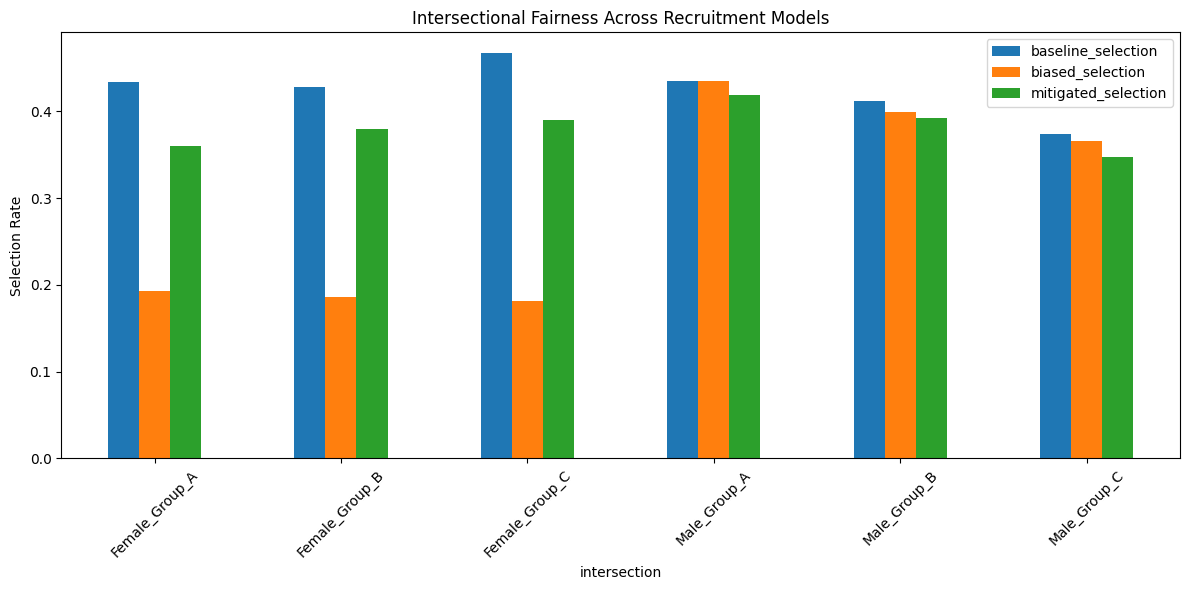

In [22]:

# STEP 13: INTERSECTIONAL FAIRNESS AUDIT

test_data["intersection"] = (
    test_data["gender_group"] + "_" +
    test_data["race_group"]
)

intersection_audit = test_data.groupby("intersection").agg(
    applicants=("applicant_id", "count"),
    qualified=("objectively_qualified", "sum"),
    baseline_selection=("baseline_prediction", "mean"),
    biased_selection=("biased_prediction", "mean"),
    mitigated_selection=("mitigated_prediction", "mean")
)

display(intersection_audit.round(4))

intersection_audit.to_csv(
    "intersectional_fairness_audit.csv"
)

intersection_audit[
    ["baseline_selection",
     "biased_selection",
     "mitigated_selection"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Intersectional Fairness Across Recruitment Models")
plt.ylabel("Selection Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:

# STEP 14: FALSE NEGATIVE RATE

def calculate_metrics(group, prediction):

    actual = group["objectively_qualified"]
    predicted = group[prediction]

    fn = ((actual == 1) & (predicted == 0)).sum()
    tp = ((actual == 1) & (predicted == 1)).sum()

    return fn / (fn + tp) if (fn + tp) else np.nan

fnr_audit = pd.DataFrame({
    model: test_data.groupby("intersection").apply(
        lambda group: calculate_metrics(group, model)
    )
    for model in models
})

fnr_audit.columns = [
    "Baseline FNR",
    "Biased FNR",
    "Mitigated FNR"
]

display(fnr_audit.round(4))


/tmp/ipykernel_2053/2698344566.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  model: test_data.groupby("intersection").apply(
/tmp/ipykernel_2053/2698344566.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  model: test_data.groupby("intersection").apply(
/tmp/ipykernel_2053/2698344566.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, an

,Baseline FNR,Biased FNR,Mitigated FNR
intersection,,,
Female_Group_A,0.3125,0.6944,0.5208
Female_Group_B,0.2090,0.6567,0.4179
Female_Group_C,0.1000,0.6500,0.4500
Male_Group_A,0.2984,0.2984,0.3246
Male_Group_B,0.3146,0.3371,0.3483
Male_Group_C,0.3065,0.3226,0.3548


In [24]:

# STEP 15: SAVE FINAL AUDIT FILES

audit_results.to_csv("gender_fairness_results.csv", index=False)
model_summary.to_csv("model_comparison.csv", index=False)
intersection_audit.to_csv("intersectional_audit.csv")
fnr_audit.to_csv("false_negative_audit.csv")

print("All fairness audit files saved successfully!")


All fairness audit files saved successfully!


In [25]:

# STEP 16: REGULATORY GOVERNANCE ANALYSIS

policy_analysis = pd.DataFrame([
    {
        "Regulatory Area": "Independent Bias Audit",
        "NYC Requirement": "Independent bias audit within one year before use",
        "Identified Gap": "Audit completion alone does not guarantee corrective action",
        "Our Recommendation": "Require documented remediation plans"
    },
    {
        "Regulatory Area": "Transparency",
        "NYC Requirement": "Public summary of audit results",
        "Identified Gap": "Candidates may still struggle to understand individual decisions",
        "Our Recommendation": "Provide understandable candidate explanations"
    },
    {
        "Regulatory Area": "Human Accountability",
        "NYC Requirement": "Employers remain responsible for compliance",
        "Identified Gap": "Operational responsibility across vendors and employers can be unclear",
        "Our Recommendation": "Define clear ownership and escalation procedures"
    },
    {
        "Regulatory Area": "Continuous Monitoring",
        "NYC Requirement": "Annual bias audit",
        "Identified Gap": "Annual audits may miss changes between audits",
        "Our Recommendation": "Introduce ongoing performance monitoring"
    },
    {
        "Regulatory Area": "Intersectional Fairness",
        "NYC Requirement": "Audit sex, race/ethnicity and intersectional categories",
        "Identified Gap": "Small sample sizes can limit meaningful subgroup analysis",
        "Our Recommendation": "Report sample sizes and uncertainty"
    }
])

display(policy_analysis)

policy_analysis.to_csv(
    "regulatory_governance_analysis.csv",
    index=False
)


,Regulatory Area,NYC Requirement,Identified Gap,Our Recommendation
0,Independent Bias Audit,Independent bias audit within one year before use,Audit completion alone does not guarantee corr...,Require documented remediation plans
1,Transparency,Public summary of audit results,Candidates may still struggle to understand in...,Provide understandable candidate explanations
2,Human Accountability,Employers remain responsible for compliance,Operational responsibility across vendors and ...,Define clear ownership and escalation procedures
3,Continuous Monitoring,Annual bias audit,Annual audits may miss changes between audits,Introduce ongoing performance monitoring
4,Intersectional Fairness,"Audit sex, race/ethnicity and intersectional c...",Small sample sizes can limit meaningful subgro...,Report sample sizes and uncertainty


In [26]:

# STEP 16B: NIST AI RMF MAPPING

nist_mapping = pd.DataFrame([
    {
        "Function": "GOVERN",
        "Application": "Assign accountability for recruitment AI",
        "Evidence": "Documented roles and approval procedures"
    },
    {
        "Function": "MAP",
        "Application": "Identify affected applicants and potential harms",
        "Evidence": "Stakeholder and risk assessment"
    },
    {
        "Function": "MEASURE",
        "Application": "Evaluate selection disparities and model performance",
        "Evidence": "Fairness metrics and audit results"
    },
    {
        "Function": "MANAGE",
        "Application": "Implement safeguards and monitor outcomes",
        "Evidence": "Mitigation and monitoring plan"
    }
])

display(nist_mapping)

nist_mapping.to_csv("nist_governance_mapping.csv", index=False)


,Function,Application,Evidence
0,GOVERN,Assign accountability for recruitment AI,Documented roles and approval procedures
1,MAP,Identify affected applicants and potential harms,Stakeholder and risk assessment
2,MEASURE,Evaluate selection disparities and model perfo...,Fairness metrics and audit results
3,MANAGE,Implement safeguards and monitor outcomes,Mitigation and monitoring plan


In [27]:

import os
import shutil

project_folder = "Recruitment_AI_Governance_Project"

os.makedirs(project_folder, exist_ok=True)

files_to_save = [
    "synthetic_recruitment_dataset.csv",
    "gender_fairness_results.csv",
    "model_comparison.csv",
    "intersectional_audit.csv",
    "false_negative_audit.csv",
    "regulatory_governance_analysis.csv",
    "nist_governance_mapping.csv"
]

for file in files_to_save:
    if os.path.exists(file):
        shutil.copy(file, project_folder)

shutil.make_archive(
    project_folder, "zip", project_folder
)

from google.colab import files
files.download(project_folder + ".zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>